# Assignment 4, steps 3 and 5: combining everyone's models
Each person saves two files (rows = the 89 AnCg libraries, index `refinebio_title`):
- `results/a4_predictions_<method>.tsv`: columns `group_pred_g<N>` (1 = disorder, 0 = control) and
  `cluster_pred_g<N>` (1 = the cluster you predict, 0 = all others), for N = 10, 100, 1000, 5000, 10000.
  Predictions must come from cross validation (e.g. `cross_val_predict`), not from the training data.
- `results/a4_signature_<method>.tsv`: columns `gene, symbol, coef, target, method`, one row per gene the model uses.

In [1]:
import glob
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

files = sorted(glob.glob("results/a4_predictions_*.tsv"))
models = {f.split("a4_predictions_")[1][:-4]: pd.read_csv(f, sep="\t", index_col=0) for f in files}
print("models:", list(models))

models: ['logreg']


## Step 3: samples x models matrix and prediction stability
For each library: how many models predict disorder vs control (3a) and the cluster vs other (3b).
Stability = share of models that agree with the majority (1 = all models agree).
3c: Spearman correlation between group stability and cluster stability, one test per gene count, BH adjusted.

In [2]:
results = []
for n in [10, 100, 1000, 5000, 10000]:
    group_matrix = pd.DataFrame({m: df[f"group_pred_g{n}"] for m, df in models.items()})
    cluster_matrix = pd.DataFrame({m: df[f"cluster_pred_g{n}"] for m, df in models.items()})
    n_models = group_matrix.shape[1]

    n_disorder = group_matrix.sum(axis=1)
    n_cluster = cluster_matrix.sum(axis=1)
    group_stability = np.maximum(n_disorder, n_models - n_disorder) / n_models
    cluster_stability = np.maximum(n_cluster, n_models - n_cluster) / n_models

    rho, p = spearmanr(group_stability, cluster_stability)
    results.append({"genes": n, "spearman_rho": rho, "p_value": p})

    if n == 5000:
        print("Samples x models matrix (group predictions, 5,000 genes):")
        print(group_matrix.head())
        print("\nNumber of models predicting disorder, per library:")
        print(n_disorder.value_counts().sort_index())

results = pd.DataFrame(results)
results["p_adj"] = multipletests(results.p_value.fillna(1), method="fdr_bh")[1]
results.to_csv("results/a4_stability_tests.tsv", sep="\t", index=False)
results

Samples x models matrix (group predictions, 5,000 genes):
                      logreg
refinebio_title             
X1834_AnCg_C_SL31501       0
X1881_AnCg_B_SL7146        1
X2208_AnCg_M_SL7409        1
X2267_AnCg_M_SL7388        0
X2292_AnCg_C_SL6660        0

Number of models predicting disorder, per library:
0    43
1    46
Name: count, dtype: int64


/tmp/ipykernel_259/2063910965.py:12: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = spearmanr(group_stability, cluster_stability)
/tmp/ipykernel_259/2063910965.py:12: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = spearmanr(group_stability, cluster_stability)
/tmp/ipykernel_259/2063910965.py:12: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = spearmanr(group_stability, cluster_stability)
/tmp/ipykernel_259/2063910965.py:12: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = spearmanr(group_stability, cluster_stability)
/tmp/ipykernel_259/2063910965.py:12: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = spearmanr(group_stability, cluster_stability)


,genes,spearman_rho,p_value,p_adj
0,10,NaN,NaN,1.0
1,100,NaN,NaN,1.0
2,1000,NaN,NaN,1.0
3,5000,NaN,NaN,1.0
4,10000,NaN,NaN,1.0


## Step 5: heatmap of every gene in any model's signature

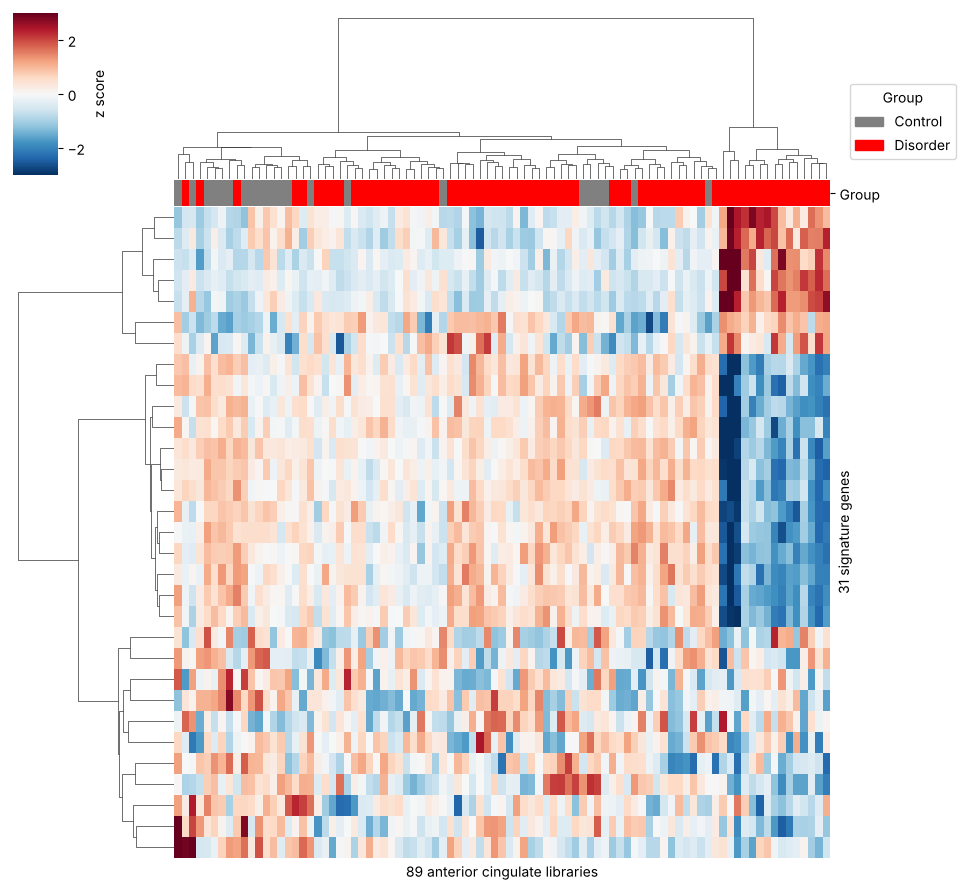

In [3]:
signatures = pd.concat([pd.read_csv(f, sep="\t") for f in glob.glob("results/a4_signature_*.tsv")])
genes = signatures.gene.unique()

expr = pd.read_csv("data/expr_by_library.tsv.gz", sep="\t", index_col=0)
meta = pd.read_csv("data/meta_by_library.tsv", sep="\t", index_col=0)
libraries = next(iter(models.values())).index
heat = np.log2(expr.loc[genes, libraries] + 1)

group = np.where(meta.loc[libraries, "dx"] == "control", "Control", "Disorder")
group_colors = pd.Series(group, index=libraries).map({"Control": "gray", "Disorder": "red"}).rename("Group")

g = sns.clustermap(heat, z_score=0, method="ward", cmap="RdBu_r", vmin=-3, vmax=3,
                   col_colors=group_colors, xticklabels=False, yticklabels=False, figsize=(9, 9),
                   cbar_kws={"label": "z score"})
g.ax_heatmap.set_xlabel(f"{len(libraries)} anterior cingulate libraries")
g.ax_heatmap.set_ylabel(f"{len(genes)} signature genes")
g.ax_heatmap.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ["gray", "red"]],
                    labels=["Control", "Disorder"], title="Group", loc="upper left", bbox_to_anchor=(1.02, 1.2))
g.savefig("plots/a4_signature_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()